In [1]:
# STEP 0: Install all required modules into the same Python this notebook runs on (run once, then restart kernel)
import sys
!{sys.executable} -m pip install requests beautifulsoup4 lxml html5lib pandas

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import re
import requests
import pandas as pd
from bs4 import BeautifulSoup
from IPython.display import Image, display

/Users/Jesan/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [3]:
r = requests.get('https://en.wikipedia.org/wiki/Steve_Jobs')
r.status_code

403

In [4]:
# Wikipedia blocks requests without a browser User-Agent (403), so we send headers
headers = {
    'User-Agent': 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/143.0.0.0 Safari/537.36'
}
r = requests.get('https://en.wikipedia.org/wiki/Steve_Jobs', headers=headers)
r.status_code

200

In [5]:
soup = BeautifulSoup(r.content, 'html.parser')
soup.head

<head>
<meta charset="utf-8"/>
<title>Steve Jobs - Wikipedia</title>
<script>(function(){var className="client-js vector-feature-language-in-header-enabled vector-feature-language-in-main-menu-disabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limited-width-clientpref-1 vector-feature-limited-width-content-enabled vector-feature-custom-font-size-clientpref-1 vector-feature-appearance-pinned-clientpref-1 skin-theme-clientpref-day vector-sticky-header-enabled vector-toc-available skin-thumbsize-clientpref-standard skin-underline-clientpref-browser";var cookie=document.cookie.match(/(?:^|; )enwikimwclientpreferences=([^;]+)/);if(cookie){cookie[1].split('%2C').forEach(function(pref){className=className.replace(new RegExp('(^| )'+pref.replace(/-clientpref-\w+$|[^\w-]+/g,'')+'-clientpref-\\w+( |$)'),'$1'+pref+'$2');});}document.documentElement.cl

In [6]:
# Same page with the other parsers
soup_lxml = BeautifulSoup(r.content, 'lxml')
print('html.parser :', soup.title.text, '| <p> tags:', len(soup.find_all('p')))
print('lxml        :', soup_lxml.title.text, '| <p> tags:', len(soup_lxml.find_all('p')))

try:
    soup_html5lib = BeautifulSoup(r.content, 'html5lib')
    print('html5lib    :', soup_html5lib.title.text, '| <p> tags:', len(soup_html5lib.find_all('p')))
except Exception:
    print('html5lib    : not installed in this kernel')

html.parser : Steve Jobs - Wikipedia | <p> tags: 118
lxml        : Steve Jobs - Wikipedia | <p> tags: 118
html5lib    : Steve Jobs - Wikipedia | <p> tags: 118


In [7]:
# Page heading and the real article body
heading = soup.find('h1', id='firstHeading')
print("Page Heading:", heading.text if heading else "Not found")

# search inside mw-content-text (the first div.mw-parser-output is an empty icon div)
content = soup.find('div', id='mw-content-text').find('div', class_='mw-parser-output')
print("Content div found:", content is not None)

Page Heading: Steve Jobs
Content div found: True


In [8]:
# ---------------- 3 PARAGRAPHS ----------------
# many <p> tags on Wikipedia are empty, so keep only paragraphs that have text
paras = [p for p in content.find_all('p') if p.get_text(strip=True)]
print("Total non-empty paragraphs:", len(paras), "\n")

for i, para in enumerate(paras[:3], start=1):
    print(f"Paragraph {i}:")
    print(re.sub(r'\[\d+\]', '', para.get_text(strip=True)))   # remove [1], [2] citation marks
    print("-" * 80)

Total non-empty paragraphs: 116 

Paragraph 1:
Steven Paul Jobs(February 24, 1955 – October 5, 2011) was an American businessman, inventor, and investor. A pioneer of thepersonal computer revolutionof the 1970s and 1980s, Jobs co-founded Apple Computer Company (nowApple Inc.) in 1976 with his early business partnerSteve Wozniak. After the company's board of directors fired him in 1985, he foundedNeXTin the same year and purchasedPixarin 1986, becoming its chairman and majority shareholder until 2007. Jobs returned to Apple in 1997 as CEO, where he was closely involved with the creation and promotion of many of the company's most influential products until his resignation in 2011.
--------------------------------------------------------------------------------
Paragraph 2:
Jobs was born in San Francisco in 1955 and adopted shortly afterward. He attendedReed Collegein 1972 before withdrawing that same year. In 1974, he traveled through India,seeking enlightenmentbefore later studyingZen 

In [9]:
# ---------------- 3 TABLES ----------------
all_tables = soup.find_all('table')
print("Total tables on the page:", len(all_tables), "\n")

for i, tbl in enumerate(all_tables[:3], start=1):
    rows = tbl.find_all('tr')
    print(f"Table {i}: class = {tbl.get('class')} | rows = {len(rows)}")
    for row in rows[:3]:                                   # first 3 rows of each table
        cells = [c.get_text(" ", strip=True) for c in row.find_all(['th', 'td'])]
        print("   ", cells)
    print("-" * 80)

Total tables on the page: 21 

Table 1: class = ['infobox', 'biography', 'vcard'] | rows = 18
    ['Steve Jobs']
    ['Jobs in 2010']
    ['Born', '( 1955-02-24 ) February 24, 1955 San Francisco, California, U.S.']
--------------------------------------------------------------------------------
Table 2: class = ['infobox'] | rows = 2
    ['External image']
    ['Jobs and Steve Wozniak with an Apple I circuit board, c. 1976.']
--------------------------------------------------------------------------------
Table 3: class = ['wikitable', 'succession-box', 'noprint'] | rows = 4
    ['Business positions']
    ['Preceded by Gil Amelio', 'CEO of Apple 1997–2011', 'Succeeded by Tim Cook']
    ['Preceded by Mike Markkula', 'Apple Chairman 1981–1985', 'Succeeded by Mike Markkula']
--------------------------------------------------------------------------------


In [10]:
# ---------------- 1 TABLE AS PROPER OUTPUT (DataFrame) ----------------
# The infobox has a label in <th> and a value in <td> for every row
infobox = soup.find('table', class_='infobox')

records = []
for row in infobox.find_all('tr'):
    th = row.find('th')
    td = row.find('td')
    if th and td:
        records.append([th.get_text(" ", strip=True), re.sub(r'\[\d+\]', '', td.get_text(" ", strip=True))])

if len(records) > 0:
    infobox_df = pd.DataFrame(records, columns=['Field', 'Value'])
    display(infobox_df)
else:
    print("Error: no infobox records found.")

,Field,Value
0,Born,"( 1955-02-24 ) February 24, 1955 San Francisco..."
1,Died,"October 5, 2011 (2011-10-05) (aged 56) Palo Al..."
2,Resting place,"Alta Mesa Memorial Park , Palo Alto, California"
3,Education,Reed College (dropped out)
4,Occupations,"Businessman, inventor, investor"
5,Years active,1971–2011
6,Known for,Pioneer of the personal computer revolution wi...
7,Title,"Co-founder, chairman , and CEO of Apple Primar..."
8,Board member of,The Walt Disney Company [ 1 ] Apple
9,Spouse,Laurene Powell ​ ( m. 1991 ) ​


Image URL : https://thumb.wikimedia.org/wikipedia/commons/thumb/a/ae/Steve_Jobs_Headshot_2010_%28cropped_6%29.jpg/250px-Steve_Jobs_Headshot_2010_%28cropped_6%29.jpg?utm_source=en.wikipedia.org&utm_campaign=parser&utm_content=thumbnail
Alt text  : Steve Jobs, a man with a short beard, hair, and glasses, stands on a stage.
Download status: 200


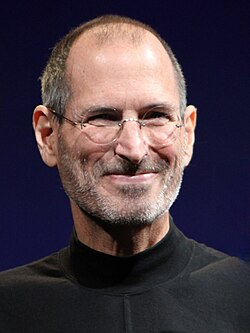

In [11]:
# ---------------- IMAGE ----------------
info_img = infobox.find('img')
img_url = info_img['src']
if img_url.startswith('//'):
    img_url = 'https:' + img_url

print("Image URL :", img_url)
print("Alt text  :", info_img.get('alt'))

img_response = requests.get(img_url, headers=headers)
print("Download status:", img_response.status_code)

with open('steve_jobs.jpg', 'wb') as f:
    f.write(img_response.content)          # save image to the notebook folder

display(Image(data=img_response.content))  # show image in the notebook